In [1]:
import pandas as pd

In [2]:
import matplotlib.pyplot as plt

In [3]:
df_16_19 = pd.read_csv("data/LNS14000012.csv")

In [4]:
df_16_19.head()

,observation_date,LNS14000012
0,1948-01-01,8.5
1,1948-02-01,10.0
2,1948-03-01,10.5
3,1948-04-01,9.5
4,1948-05-01,7.0


In [5]:
df_16_19["observation_date"] = pd.to_datetime(df_16_19["observation_date"])

In [6]:
df_20_24 = pd.read_csv("data/LNS14000036.csv")

In [7]:
df_20_24["observation_date"] = pd.to_datetime(df_20_24["observation_date"])

In [8]:
df_20_24["observation_date"] = pd.to_datetime(df_20_24["observation_date"])

In [9]:
df_25_34 = pd.read_csv("data/LNS14000089.csv")

In [10]:
df_25_34.head()

,observation_date,LNS14000089
0,1948-01-01,3.0
1,1948-02-01,3.3
2,1948-03-01,2.9
3,1948-04-01,3.4
4,1948-05-01,3.0


In [11]:
df_25_34["observation_date"] = pd.to_datetime(df_25_34["observation_date"])

In [12]:
df_35_44 = pd.read_csv("data/LNS14024230.csv")

In [13]:
df_35_44.head()

,observation_date,LNS14024230
0,1948-01-01,2.9
1,1948-02-01,3.1
2,1948-03-01,3.0
3,1948-04-01,3.0
4,1948-05-01,3.1


In [14]:
df_35_44["observation_date"] = pd.to_datetime(df_35_44["observation_date"])

In [15]:
df_16_19 = df_16_19.rename(columns={"LNS14000012": "unemployment_rate"})

In [16]:
df_20_24 = df_20_24.rename(columns={"LNS14000036": "unemployment_rate"})

In [17]:
df_25_34 = df_25_34.rename(columns={"LNS14000089": "unemployment_rate"})

In [18]:
df_35_44 = df_35_44.rename(columns={"LNS14024230": "unemployment_rate"})

In [19]:
df_16_19.head()

,observation_date,unemployment_rate
0,1948-01-01,8.5
1,1948-02-01,10.0
2,1948-03-01,10.5
3,1948-04-01,9.5
4,1948-05-01,7.0


In [20]:
df_16_19["age_group"] = "16-19"

In [21]:
df_20_24["age_group"] = "20-24"

In [22]:
df_25_34["age_group"] = "25-34"

In [23]:
df_35_44["age_group"] = "35-44"

In [24]:
df = pd.concat([df_16_19, df_20_24, df_25_34, df_35_44], ignore_index=True)

In [25]:
df.head()

,observation_date,unemployment_rate,age_group
0,1948-01-01,8.5,16-19
1,1948-02-01,10.0,16-19
2,1948-03-01,10.5,16-19
3,1948-04-01,9.5,16-19
4,1948-05-01,7.0,16-19


In [26]:
df["age_group"].value_counts()

age_group
16-19    944
20-24    944
25-34    944
35-44    944
Name: count, dtype: int64

In [27]:
df.isnull().sum()

observation_date     0
unemployment_rate    4
age_group            0
dtype: int64

In [28]:
df[df["unemployment_rate"].isnull()]

,observation_date,unemployment_rate,age_group
933,2025-10-01,NaN,16-19
1877,2025-10-01,NaN,20-24
2821,2025-10-01,NaN,25-34
3765,2025-10-01,NaN,35-44


In [29]:
df = df.dropna(subset=["unemployment_rate"])

In [30]:
df.isnull().sum()

observation_date     0
unemployment_rate    0
age_group            0
dtype: int64

In [31]:
df_35_44["age_group"] = "55+"

In [32]:
df = pd.concat([df_16_19, df_20_24, df_25_34, df_35_44], ignore_index=True)

In [33]:
df = df.dropna(subset=["unemployment_rate"])

In [34]:
df["age_group"].value_counts()

age_group
16-19    943
20-24    943
25-34    943
55+      943
Name: count, dtype: int64

In [35]:
df["observation_date"].min(), df["observation_date"].max()

(Timestamp('1948-01-01 00:00:00'), Timestamp('2026-08-01 00:00:00'))

In [36]:
df.groupby("age_group")["unemployment_rate"].describe()

,count,mean,std,min,25%,50%,75%,max
age_group,,,,,,,,
16-19,943.0,15.904030,3.920284,6.4,13.4,15.9,17.90,32.8
20-24,943.0,9.219194,2.678102,3.5,7.4,9.0,10.65,25.5
25-34,943.0,5.453659,1.853219,1.9,4.1,5.2,6.50,14.6
55+,943.0,3.777837,1.184833,1.7,3.0,3.5,4.30,13.6


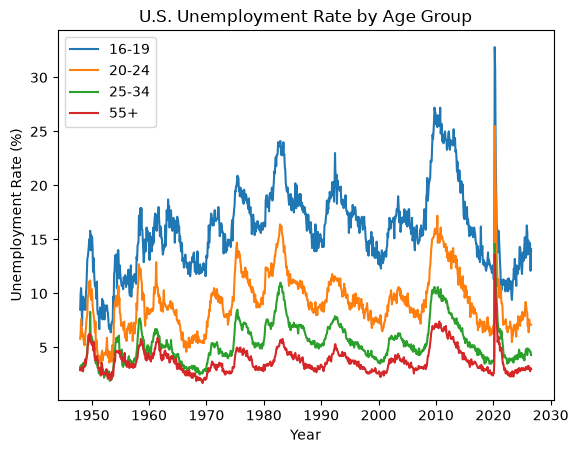

In [37]:
for group in ["16-19", "20-24", "25-34", "55+"]:
    temp = df[df["age_group"] == group]
    plt.plot(temp["observation_date"], temp["unemployment_rate"], label=group)

plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")
plt.title("U.S. Unemployment Rate by Age Group")
plt.legend()
plt.show()

In [38]:
df_recent = df[df["observation_date"] >= "2000-01-01"].copy()

In [39]:
df_recent.groupby("age_group").size()

age_group
16-19    319
20-24    319
25-34    319
55+      319
dtype: int64

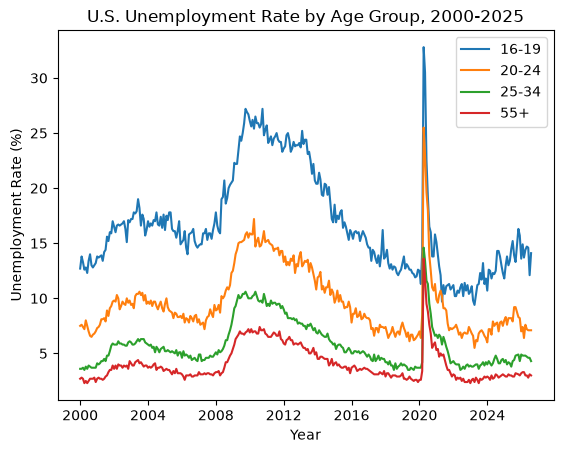

In [40]:
for group in ["16-19", "20-24", "25-34", "55+"]:
    temp = df_recent[df_recent["age_group"] == group]
    plt.plot(temp["observation_date"], temp["unemployment_rate"], label=group)

plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")
plt.title("U.S. Unemployment Rate by Age Group, 2000-2025")
plt.legend()
plt.show()

In [41]:
teen = df_recent[df_recent["age_group"] == "16-19"].copy()

In [42]:
teen = teen.sort_values("observation_date")

In [43]:
teen = teen.set_index("observation_date")

In [44]:
teen.head()

,unemployment_rate,age_group
observation_date,,
2000-01-01,12.7,16-19
2000-02-01,13.8,16-19
2000-03-01,13.3,16-19
2000-04-01,12.6,16-19
2000-05-01,12.8,16-19


In [45]:
teen = teen.asfreq("MS")

In [46]:
teen.isnull().sum()

unemployment_rate    1
age_group            1
dtype: int64

In [47]:
teen = teen.dropna()

In [48]:
teen.isnull().sum()

unemployment_rate    0
age_group            0
dtype: int64

In [49]:
y = teen["unemployment_rate"]

In [50]:
y.head()

observation_date
2000-01-01    12.7
2000-02-01    13.8
2000-03-01    13.3
2000-04-01    12.6
2000-05-01    12.8
Name: unemployment_rate, dtype: float64

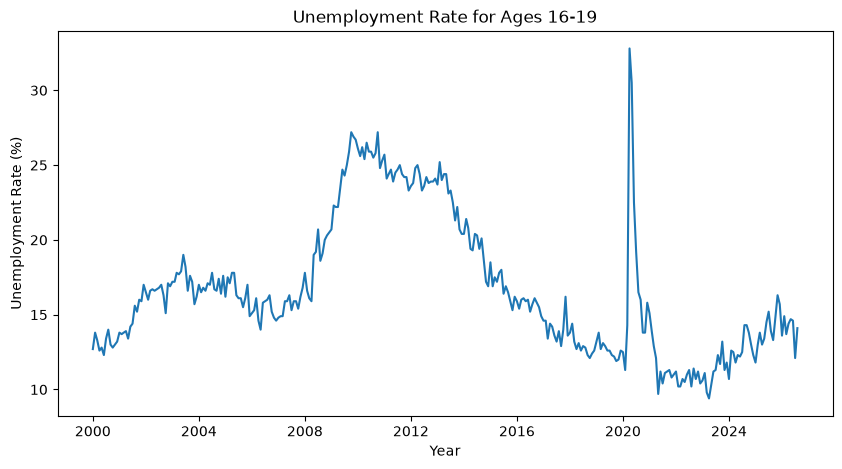

In [51]:
plt.figure(figsize=(10,5))
plt.plot(y)
plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")
plt.title("Unemployment Rate for Ages 16-19")
plt.show()

In [52]:
from statsmodels.tsa.stattools import kpss

In [53]:
kpss_result = kpss(y, regression="c", nlags="auto")

C:\Users\nanil\AppData\Local\Temp\ipykernel_65260\15816014.py:1: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(y, regression="c", nlags="auto")


In [54]:
kpss_result[0]

np.float64(0.8219669091752759)

In [55]:
kpss_result[1]

np.float64(0.01)

In [56]:
print("KPSS Statistic:", kpss_result[0])
print("p-value:", kpss_result[1])

KPSS Statistic: 0.8219669091752759
p-value: 0.01


In [57]:
y_diff = y.diff().dropna()

In [58]:
y_diff.head()

observation_date
2000-02-01    1.1
2000-03-01   -0.5
2000-04-01   -0.7
2000-05-01    0.2
2000-06-01   -0.5
Name: unemployment_rate, dtype: float64

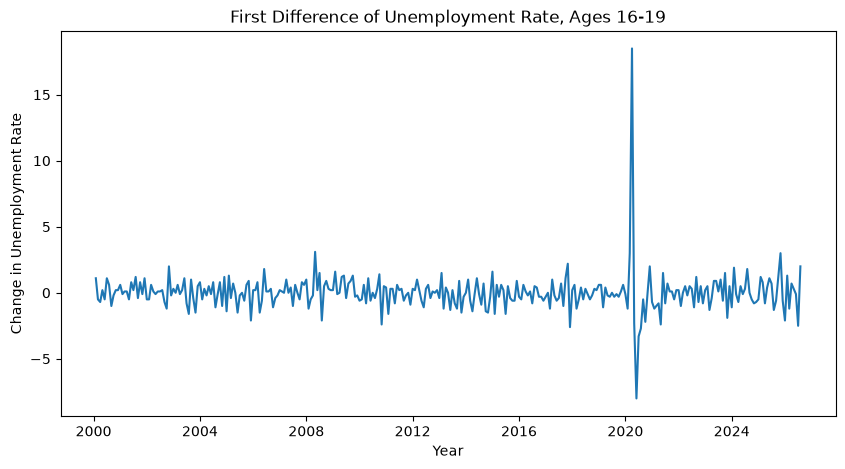

In [59]:
plt.figure(figsize=(10,5))
plt.plot(y_diff)
plt.xlabel("Year")
plt.ylabel("Change in Unemployment Rate")
plt.title("First Difference of Unemployment Rate, Ages 16-19")
plt.show()

In [60]:
kpss_diff = kpss(y_diff, regression="c", nlags="auto")

C:\Users\nanil\AppData\Local\Temp\ipykernel_65260\329924493.py:1: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_diff = kpss(y_diff, regression="c", nlags="auto")


In [61]:
print("KPSS Statistic:", kpss_diff[0])
print("p-value:", kpss_diff[1])

KPSS Statistic: 0.13163692291964554
p-value: 0.1


In [62]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

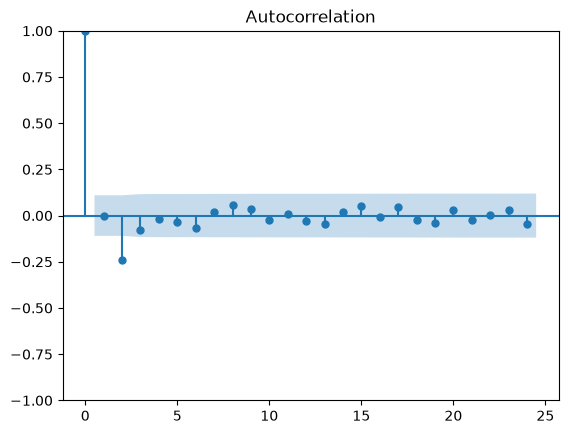

In [63]:
plot_acf(y_diff, lags=24)
plt.show()

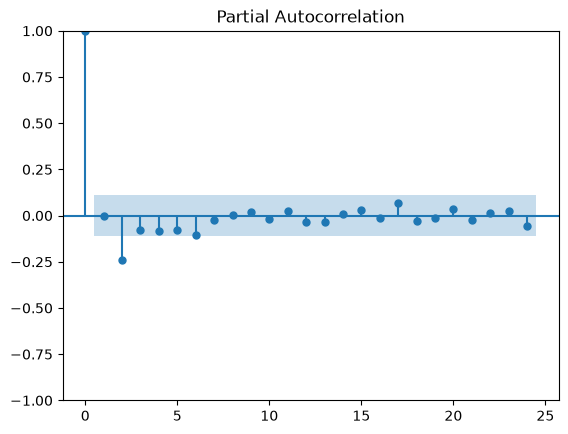

In [64]:
plot_pacf(y_diff, lags=24)
plt.show()

In [65]:
from statsmodels.tsa.arima.model import ARIMA

In [66]:
models = [(1,1,0), (2,1,0), (0,1,1), (0,1,2), (1,1,1), (2,1,2)]

for order in models:
    model = ARIMA(y, order=order)
    result = model.fit()
    print(order, "AIC =", result.aic)

C:\Users\nanil\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\nanil\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\nanil\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\nanil\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(d

(1, 1, 0) AIC = 1151.1169606998149
(2, 1, 0) AIC = 1133.6319381504613
(0, 1, 1) AIC = 1151.1169027695003


C:\Users\nanil\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\nanil\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\nanil\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\nanil\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(d

(0, 1, 2) AIC = 1129.1602161467872
(1, 1, 1) AIC = 1138.3261529825536


C:\Users\nanil\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\nanil\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\nanil\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


(2, 1, 2) AIC = 1129.536741649872


In [67]:
y = teen["unemployment_rate"].asfreq("MS")

In [68]:
y.isnull().sum()

np.int64(1)

In [69]:
y[y.isnull()]

observation_date
2025-10-01   NaN
Freq: MS, Name: unemployment_rate, dtype: float64

In [70]:
y = y.interpolate()

In [71]:
y.isnull().sum()

np.int64(0)

In [72]:
models = [(1,1,0), (2,1,0), (0,1,1), (0,1,2), (1,1,1), (2,1,2)]

for order in models:
    model = ARIMA(y, order=order)
    result = model.fit()
    print(order, "AIC =", result.aic)

(1, 1, 0) AIC = 1151.611464851946
(2, 1, 0) AIC = 1134.492417480766
(0, 1, 1) AIC = 1151.5994427496016
(0, 1, 2) AIC = 1130.5214052586125
(1, 1, 1) AIC = 1139.1129449470973
(2, 1, 2) AIC = 1130.1061365239245


In [73]:
final_model = ARIMA(y, order=(2,1,2))
final_result = final_model.fit()

In [74]:
print(final_result.summary())

                               SARIMAX Results                                
Dep. Variable:      unemployment_rate   No. Observations:                  320
Model:                 ARIMA(2, 1, 2)   Log Likelihood                -560.053
Date:                Wed, 30 Sep 2026   AIC                           1130.106
Time:                        18:23:46   BIC                           1148.932
Sample:                    01-01-2000   HQIC                          1137.625
                         - 08-01-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3970      0.250      1.587      0.112      -0.093       0.887
ar.L2         -0.0475      0.193     -0.247      0.805      -0.425       0.330
ma.L1         -0.4314      0.248     -1.739      0.0

In [75]:
residuals = final_result.resid

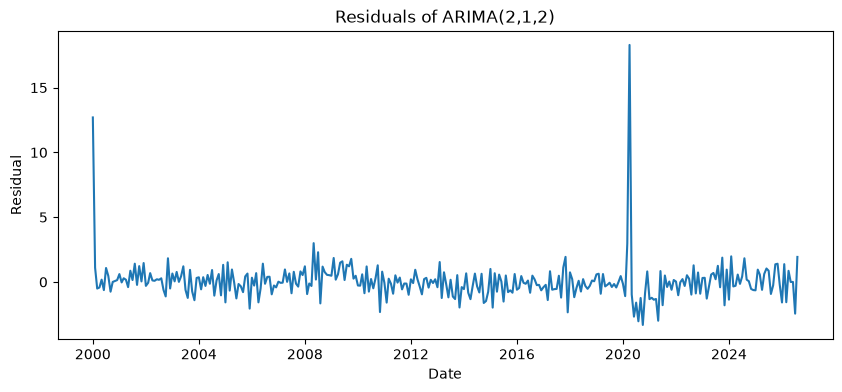

In [76]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))
plt.plot(residuals)
plt.title("Residuals of ARIMA(2,1,2)")
plt.xlabel("Date")
plt.ylabel("Residual")
plt.show()

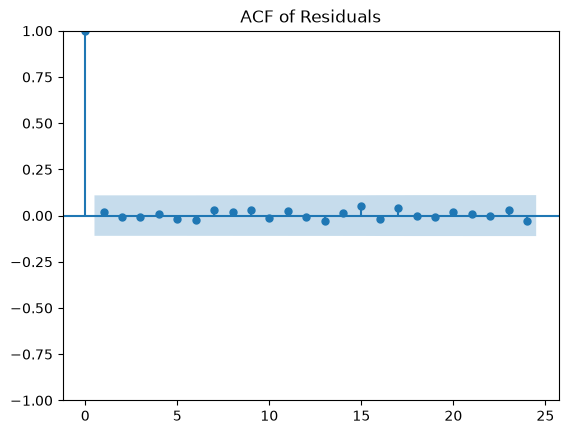

In [77]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(residuals.dropna(), lags=24)
plt.title("ACF of Residuals")
plt.show()

In [78]:
from statsmodels.stats.diagnostic import acorr_ljungbox

ljung_box = acorr_ljungbox(residuals.dropna(), lags=[12], return_df=True)
ljung_box

,lb_stat,lb_pvalue
12,1.496264,0.999871


In [79]:
forecast = final_result.get_forecast(steps=12)
forecast_mean = forecast.predicted_mean
forecast_ci = forecast.conf_int()

In [80]:
forecast_mean

2026-09-01    14.707218
2026-10-01    14.436541
2026-11-01    14.300211
2026-12-01    14.258952
2027-01-01    14.249053
2027-02-01    14.247084
2027-03-01    14.246773
2027-04-01    14.246743
2027-05-01    14.246746
2027-06-01    14.246748
2027-07-01    14.246749
2027-08-01    14.246749
Freq: MS, Name: predicted_mean, dtype: float64

In [81]:
forecast_ci

,lower unemployment_rate,upper unemployment_rate
2026-09-01,11.963618,17.450818
2026-10-01,10.622694,18.250388
2026-11-01,10.043975,18.556446
2026-12-01,9.714602,18.803303
2027-01-01,9.460240,19.037866
2027-02-01,9.231191,19.262976
2027-03-01,9.014615,19.478931
2027-04-01,8.807040,19.686445
2027-05-01,8.607139,19.886352
2027-06-01,8.414082,20.079414


In [82]:
forecast_dates = pd.date_range(
    start=y.index[-1] + pd.offsets.MonthBegin(1),
    periods=12,
    freq="MS"
)

forecast_mean.index = forecast_dates
forecast_ci.index = forecast_dates

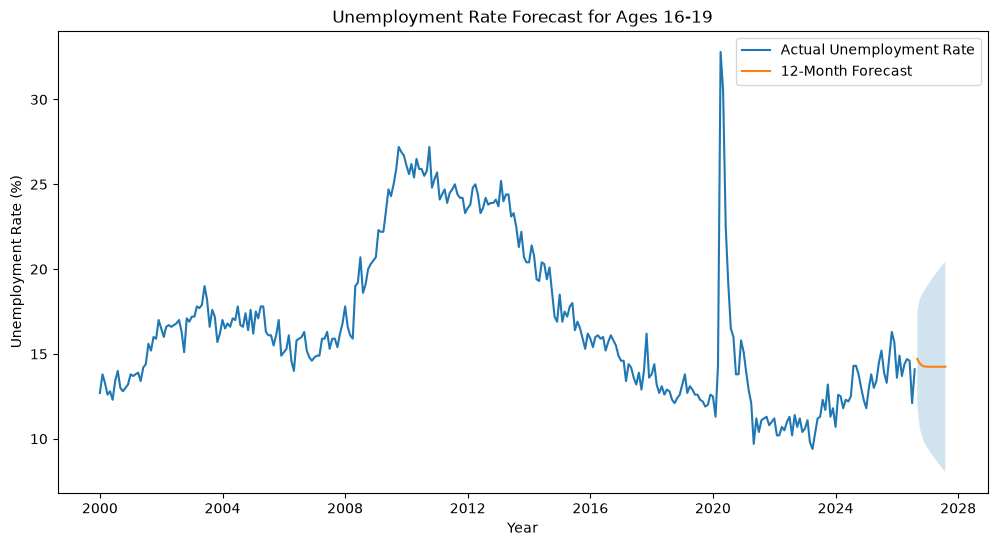

In [83]:
plt.figure(figsize=(12,6))

plt.plot(y, label="Actual Unemployment Rate")
plt.plot(forecast_mean, label="12-Month Forecast")

plt.fill_between(
    forecast_ci.index,
    forecast_ci.iloc[:, 0],
    forecast_ci.iloc[:, 1],
    alpha=0.2
)

plt.title("Unemployment Rate Forecast for Ages 16-19")
plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")
plt.legend()
plt.show()

In [84]:
forecast_table = pd.DataFrame({
    "Forecast": forecast_mean,
    "Lower CI": forecast_ci.iloc[:, 0],
    "Upper CI": forecast_ci.iloc[:, 1]
})

forecast_table

,Forecast,Lower CI,Upper CI
2026-09-01,14.707218,11.963618,17.450818
2026-10-01,14.436541,10.622694,18.250388
2026-11-01,14.300211,10.043975,18.556446
2026-12-01,14.258952,9.714602,18.803303
2027-01-01,14.249053,9.460240,19.037866
2027-02-01,14.247084,9.231191,19.262976
2027-03-01,14.246773,9.014615,19.478931
2027-04-01,14.246743,8.807040,19.686445
2027-05-01,14.246746,8.607139,19.886352
2027-06-01,14.246748,8.414082,20.079414


In [85]:
print("First forecast:", forecast_mean.iloc[0])
print("Last forecast:", forecast_mean.iloc[-1])
print("Minimum forecast:", forecast_mean.min())
print("Maximum forecast:", forecast_mean.max())

First forecast: 14.70721793637451
Last forecast: 14.24674933584215
Minimum forecast: 14.246742729800358
Maximum forecast: 14.70721793637451


In [86]:
print("Forecast starts:", forecast_mean.index[0])
print("Forecast ends:", forecast_mean.index[-1])

Forecast starts: 2026-09-01 00:00:00
Forecast ends: 2027-08-01 00:00:00


In [87]:
forecast_table.to_csv("unemployment_forecast.csv")

In [88]:
y.describe()

count    320.000000
mean      16.729688
std        4.567394
min        9.400000
25%       13.275000
50%       15.900000
75%       19.000000
max       32.800000
Name: unemployment_rate, dtype: float64

In [89]:
print("Start date:", y.index.min())
print("End date:", y.index.max())

Start date: 2000-01-01 00:00:00
End date: 2026-08-01 00:00:00


In [90]:
df.groupby("age_group")["unemployment_rate"].describe()

,count,mean,std,min,25%,50%,75%,max
age_group,,,,,,,,
16-19,943.0,15.904030,3.920284,6.4,13.4,15.9,17.90,32.8
20-24,943.0,9.219194,2.678102,3.5,7.4,9.0,10.65,25.5
25-34,943.0,5.453659,1.853219,1.9,4.1,5.2,6.50,14.6
55+,943.0,3.777837,1.184833,1.7,3.0,3.5,4.30,13.6


In [91]:
df_2000 = df[df["observation_date"] >= "2000-01-01"]

df_2000.groupby("age_group")["unemployment_rate"].describe()

,count,mean,std,min,25%,50%,75%,max
age_group,,,,,,,,
16-19,319.0,16.735737,4.573286,9.4,13.25,15.9,19.00,32.8
20-24,319.0,9.681191,2.997151,5.5,7.40,8.9,10.80,25.5
25-34,319.0,5.785580,2.050628,3.5,4.30,5.1,6.55,14.6
55+,319.0,4.030094,1.582522,2.3,3.00,3.5,4.55,13.6


In [92]:
series = {}

for group in ["16-19", "20-24", "25-34", "55+"]:
    temp = df_2000[df_2000["age_group"] == group].copy()
    temp = temp.set_index("observation_date")
    temp = temp["unemployment_rate"].asfreq("MS")
    temp = temp.interpolate()
    series[group] = temp

In [93]:
for group, data in series.items():
    print(group, ":", len(data), "observations,", data.isnull().sum(), "missing")

16-19 : 320 observations, 0 missing
20-24 : 320 observations, 0 missing
25-34 : 320 observations, 0 missing
55+ : 320 observations, 0 missing


In [94]:
for group, data in series.items():
    result = kpss(data, regression="c", nlags="auto")
    print(group)
    print("KPSS Statistic:", result[0])
    print("p-value:", result[1])
    print()

16-19
KPSS Statistic: 0.8247160342414955
p-value: 0.01

20-24
KPSS Statistic: 0.4937188236357212
p-value: 0.04308134602799072

25-34
KPSS Statistic: 0.4454482210423706
p-value: 0.05756542196449545

55+
KPSS Statistic: 0.34003049104024696
p-value: 0.1



C:\Users\nanil\AppData\Local\Temp\ipykernel_65260\3305076794.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  result = kpss(data, regression="c", nlags="auto")
C:\Users\nanil\AppData\Local\Temp\ipykernel_65260\3305076794.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result = kpss(data, regression="c", nlags="auto")


In [95]:
series_diff = {}

for group in ["16-19", "20-24"]:
    series_diff[group] = series[group].diff().dropna()

for group in ["25-34", "55+"]:
    series_diff[group] = series[group]

print("Differencing completed for all 4 age groups.")

Differencing completed for all 4 age groups.


In [96]:
for group, data in series_diff.items():
    result = kpss(data, regression="c", nlags="auto")
    print(group)
    print("KPSS Statistic:", result[0])
    print("p-value:", result[1])
    print()

16-19
KPSS Statistic: 0.13212380095381254
p-value: 0.1

20-24
KPSS Statistic: 0.04716726945234958
p-value: 0.1

25-34
KPSS Statistic: 0.4454482210423706
p-value: 0.05756542196449545

55+
KPSS Statistic: 0.34003049104024696
p-value: 0.1



C:\Users\nanil\AppData\Local\Temp\ipykernel_65260\1416064163.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result = kpss(data, regression="c", nlags="auto")
C:\Users\nanil\AppData\Local\Temp\ipykernel_65260\1416064163.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result = kpss(data, regression="c", nlags="auto")
C:\Users\nanil\AppData\Local\Temp\ipykernel_65260\1416064163.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result = kpss(data, regression="c", nlags="auto")


Age Group: 16-19


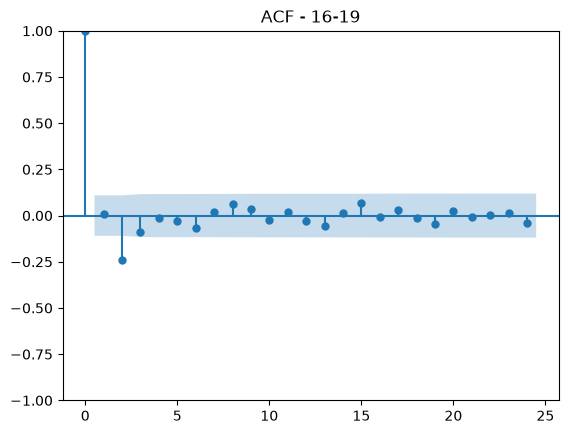

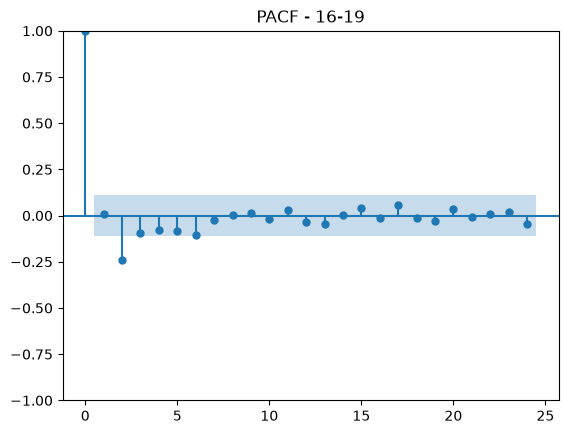

Age Group: 20-24


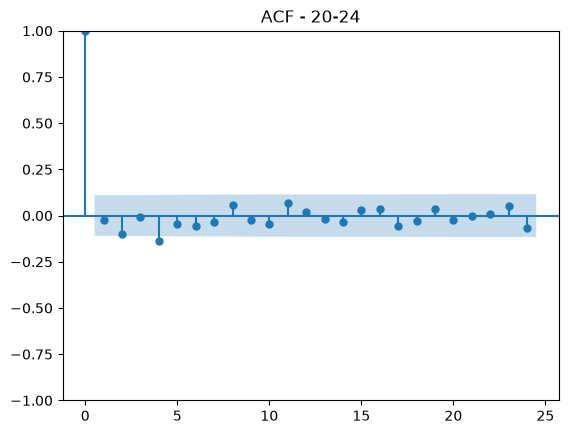

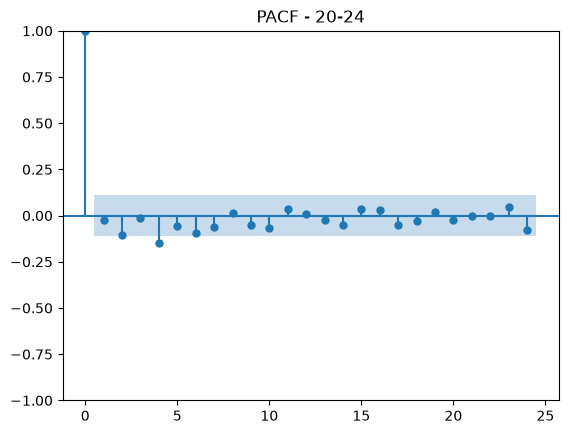

Age Group: 25-34


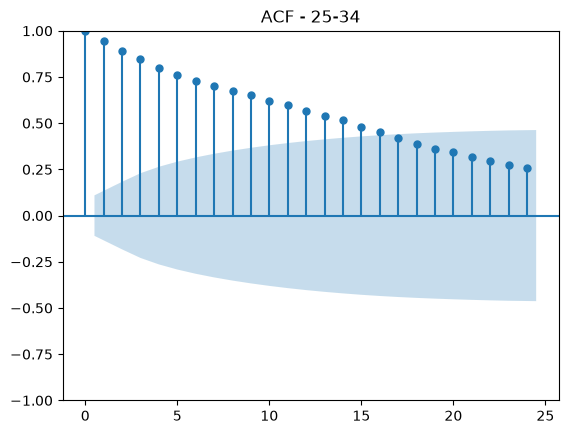

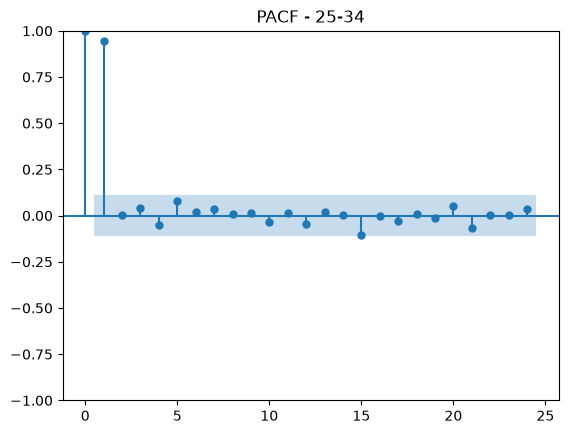

Age Group: 55+


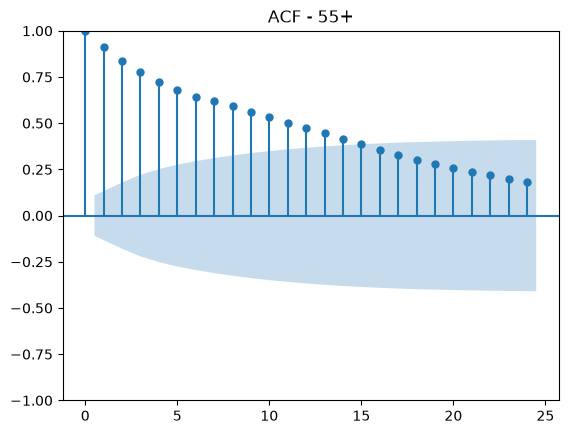

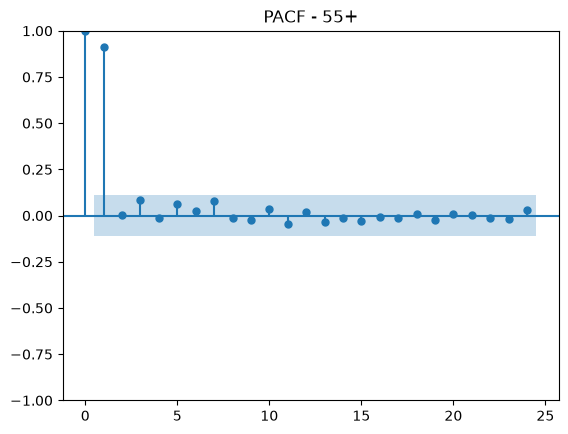

In [97]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

for group, data in series_diff.items():
    print("Age Group:", group)

    plot_acf(data, lags=24)
    plt.title("ACF - " + group)
    plt.show()

    plot_pacf(data, lags=24)
    plt.title("PACF - " + group)
    plt.show()

In [98]:
series_diff = {}

for group, data in series.items():
    series_diff[group] = data.diff().dropna()

for group, data in series_diff.items():
    result = kpss(data, regression="c", nlags="auto")
    
    print(group)
    print("KPSS Statistic:", result[0])
    print("p-value:", result[1])
    print()

16-19
KPSS Statistic: 0.13212380095381254
p-value: 0.1

20-24
KPSS Statistic: 0.04716726945234958
p-value: 0.1

25-34
KPSS Statistic: 0.05971932512808121
p-value: 0.1

55+
KPSS Statistic: 0.050019811029676085
p-value: 0.1



C:\Users\nanil\AppData\Local\Temp\ipykernel_65260\3596067459.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result = kpss(data, regression="c", nlags="auto")
C:\Users\nanil\AppData\Local\Temp\ipykernel_65260\3596067459.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result = kpss(data, regression="c", nlags="auto")
C:\Users\nanil\AppData\Local\Temp\ipykernel_65260\3596067459.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result = kpss(data, regression="c", nlags="auto")
C:\Users\nanil\AppData\Local\Temp\ipykernel_65260\3596067459.py:7: InterpolationWarning: The test statistic is outside of the range of p-value

In [99]:
from statsmodels.tsa.arima.model import ARIMA

models = [(1,1,0), (2,1,0), (0,1,1), (0,1,2), (1,1,1), (2,1,2)]

for group, data in series.items():
    print("\nAge Group:", group)
    
    for order in models:
        model = ARIMA(data, order=order)
        result = model.fit()
        print(order, "AIC =", result.aic)


Age Group: 16-19
(1, 1, 0) AIC = 1151.611464851946
(2, 1, 0) AIC = 1134.492417480766
(0, 1, 1) AIC = 1151.5994427496016
(0, 1, 2) AIC = 1130.5214052586125
(1, 1, 1) AIC = 1139.1129449470973
(2, 1, 2) AIC = 1130.1061365239245

Age Group: 20-24
(1, 1, 0) AIC = 1004.9510198185941
(2, 1, 0) AIC = 1003.596202873259
(0, 1, 1) AIC = 1004.9066192019134
(0, 1, 2) AIC = 1002.0130985601082
(1, 1, 1) AIC = 997.0134631858796


C:\Users\nanil\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


(2, 1, 2) AIC = 997.7160863877198

Age Group: 25-34
(1, 1, 0) AIC = 651.0082823957856
(2, 1, 0) AIC = 651.4992563513063
(0, 1, 1) AIC = 650.958012193656
(0, 1, 2) AIC = 651.1828398984204


C:\Users\nanil\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


(1, 1, 1) AIC = 647.6619621940041


C:\Users\nanil\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


(2, 1, 2) AIC = 650.2685940397355

Age Group: 55+
(1, 1, 0) AIC = 633.526310322101
(2, 1, 0) AIC = 630.2654155503882
(0, 1, 1) AIC = 633.3027240937158
(0, 1, 2) AIC = 628.5797762803792
(1, 1, 1) AIC = 625.658048866658
(2, 1, 2) AIC = 627.5278858561187


In [100]:
best_orders = {
    "16-19": (2,1,2),
    "20-24": (2,1,2),
    "25-34": (0,1,1),
    "55+": (1,1,1)
}

best_orders

{'16-19': (2, 1, 2), '20-24': (2, 1, 2), '25-34': (0, 1, 1), '55+': (1, 1, 1)}

In [101]:
final_models = {}

for group, data in series.items():
    order = best_orders[group]
    
    model = ARIMA(data, order=order)
    result = model.fit()
    
    final_models[group] = result
    
    print("Age Group:", group)
    print("ARIMA Model:", order)
    print("AIC:", result.aic)
    print()

Age Group: 16-19
ARIMA Model: (2, 1, 2)
AIC: 1130.1061365239245



C:\Users\nanil\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


Age Group: 20-24
ARIMA Model: (2, 1, 2)
AIC: 997.7160863877198

Age Group: 25-34
ARIMA Model: (0, 1, 1)
AIC: 650.958012193656

Age Group: 55+
ARIMA Model: (1, 1, 1)
AIC: 625.658048866658



In [102]:
forecasts = {}

for group, result in final_models.items():
    forecast = result.get_forecast(steps=12)
    forecasts[group] = forecast.predicted_mean

    print("Age Group:", group)
    print(forecast.predicted_mean)
    print()

Age Group: 16-19
2026-09-01    14.707218
2026-10-01    14.436541
2026-11-01    14.300211
2026-12-01    14.258952
2027-01-01    14.249053
2027-02-01    14.247084
2027-03-01    14.246773
2027-04-01    14.246743
2027-05-01    14.246746
2027-06-01    14.246748
2027-07-01    14.246749
2027-08-01    14.246749
Freq: MS, Name: predicted_mean, dtype: float64

Age Group: 20-24
2026-09-01    7.255409
2026-10-01    7.222192
2026-11-01    7.307687
2026-12-01    7.293489
2027-01-01    7.340733
2027-02-01    7.335221
2027-03-01    7.361450
2027-04-01    7.359720
2027-05-01    7.374351
2027-06-01    7.374141
2027-07-01    7.382341
2027-08-01    7.382649
Freq: MS, Name: predicted_mean, dtype: float64

Age Group: 25-34
2026-09-01    4.311012
2026-10-01    4.311012
2026-11-01    4.311012
2026-12-01    4.311012
2027-01-01    4.311012
2027-02-01    4.311012
2027-03-01    4.311012
2027-04-01    4.311012
2027-05-01    4.311012
2027-06-01    4.311012
2027-07-01    4.311012
2027-08-01    4.311012
Freq: MS, Nam

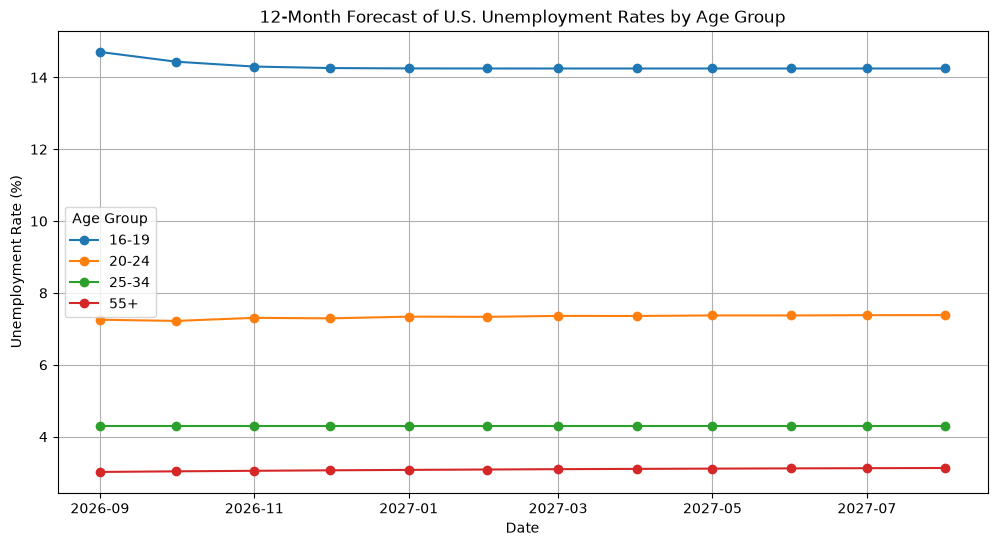

In [105]:
plt.figure(figsize=(12,6))

for group, forecast in forecasts.items():
    plt.plot(forecast.index, forecast.values, marker="o", label=group)

plt.title("12-Month Forecast of U.S. Unemployment Rates by Age Group")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.legend(title="Age Group")
plt.grid(True)
plt.show()

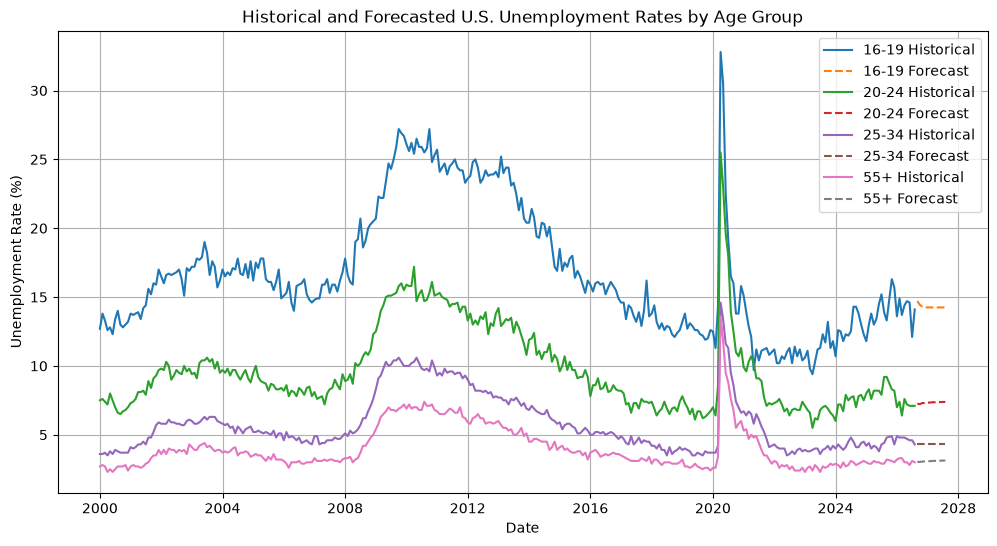

In [106]:
age_groups = ["16-19", "20-24", "25-34", "55+"]

plt.figure(figsize=(12,6))

for group in age_groups:
    historical = series[group]
    forecast = forecasts[group]

    plt.plot(historical.index, historical.values, label=f"{group} Historical")
    plt.plot(forecast.index, forecast.values, linestyle="--",
             label=f"{group} Forecast")

plt.title("Historical and Forecasted U.S. Unemployment Rates by Age Group")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.legend()
plt.grid(True)
plt.show()

In [107]:
test_size = 12

for group in age_groups:
    data = series[group]
    
    train = data.iloc[:-test_size]
    test = data.iloc[-test_size:]
    
    print(group)
    print("Training observations:", len(train))
    print("Testing observations:", len(test))
    print()

16-19
Training observations: 308
Testing observations: 12

20-24
Training observations: 308
Testing observations: 12

25-34
Training observations: 308
Testing observations: 12

55+
Training observations: 308
Testing observations: 12



In [108]:
from statsmodels.tsa.arima.model import ARIMA

model_orders = {
    "16-19": (2,1,2),
    "20-24": (2,1,2),
    "25-34": (0,1,1),
    "55+": (1,1,1)
}

test_predictions = {}

for group in age_groups:
    data = series[group]
    
    train = data.iloc[:-12]
    test = data.iloc[-12:]
    
    model = ARIMA(train, order=model_orders[group])
    fitted_model = model.fit()
    
    predictions = fitted_model.forecast(steps=12)
    test_predictions[group] = predictions
    
    print(group)
    print("Forecast complete")
    print()

16-19
Forecast complete



C:\Users\nanil\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


20-24
Forecast complete

25-34
Forecast complete

55+
Forecast complete



In [109]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

for group in age_groups:
    actual = series[group].iloc[-12:]
    predicted = test_predictions[group]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    print("Age Group:", group)
    print("MAE:", round(mae, 3))
    print("RMSE:", round(rmse, 3))
    print()

Age Group: 16-19
MAE: 0.968
RMSE: 1.215

Age Group: 20-24
MAE: 1.052
RMSE: 1.218

Age Group: 25-34
MAE: 0.332
RMSE: 0.361

Age Group: 55+
MAE: 0.154
RMSE: 0.18



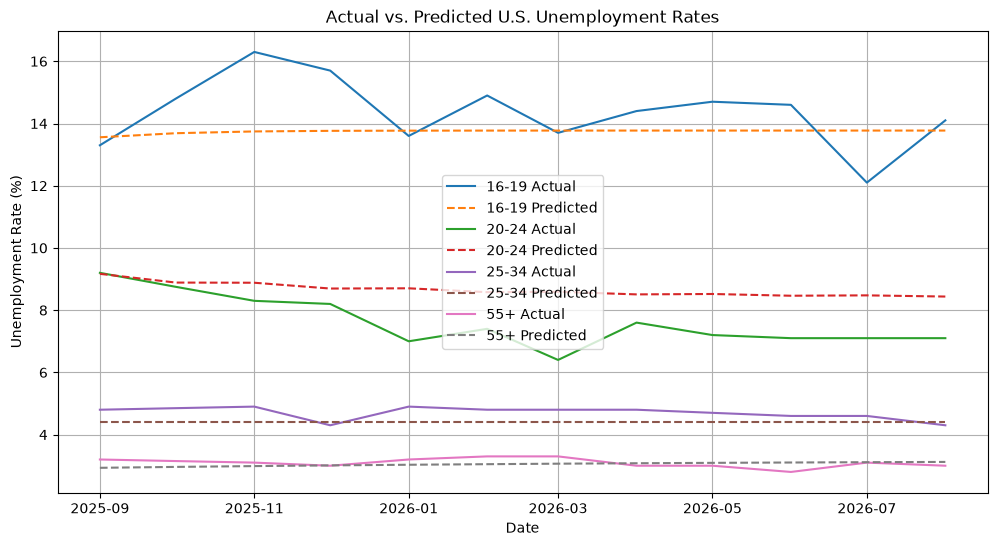

In [110]:
plt.figure(figsize=(12,6))

for group in age_groups:
    actual = series[group].iloc[-12:]
    predicted = test_predictions[group]

    plt.plot(actual.index, actual.values,
             label=f"{group} Actual")

    plt.plot(actual.index, predicted.values,
             linestyle="--",
             label=f"{group} Predicted")

plt.title("Actual vs. Predicted U.S. Unemployment Rates")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.legend()
plt.grid(True)
plt.show()

In [111]:
accuracy_results = []

for group in age_groups:
    actual = series[group].iloc[-12:]
    predicted = test_predictions[group]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    accuracy_results.append({
        "Age Group": group,
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3)
    })

accuracy_table = pd.DataFrame(accuracy_results)

accuracy_table

,Age Group,MAE,RMSE
0,16-19,0.968,1.215
1,20-24,1.052,1.218
2,25-34,0.332,0.361
3,55+,0.154,0.180


In [112]:
residuals = {}

for group in age_groups:
    actual = series[group].iloc[-12:]
    predicted = test_predictions[group]

    residuals[group] = actual.values - predicted.values

    print("Age Group:", group)
    print("Mean Residual:", round(residuals[group].mean(), 3))
    print()

Age Group: 16-19
Mean Residual: 0.606

Age Group: 20-24
Mean Residual: -1.046

Age Group: 25-34
Mean Residual: 0.3

Age Group: 55+
Mean Residual: 0.05



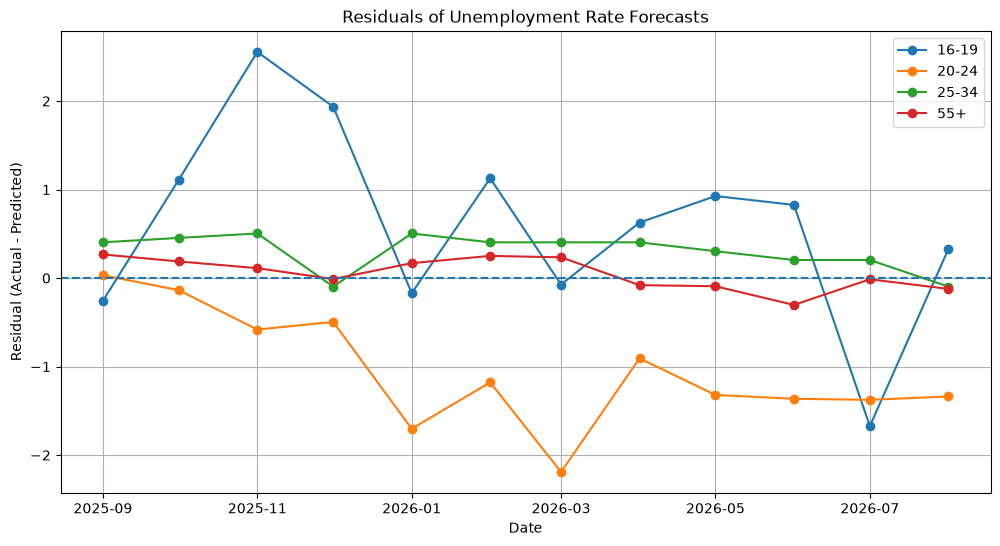

In [113]:
plt.figure(figsize=(12,6))

for group in age_groups:
    plt.plot(test.index, residuals[group], marker="o", label=group)

plt.axhline(y=0, linestyle="--")

plt.title("Residuals of Unemployment Rate Forecasts")
plt.xlabel("Date")
plt.ylabel("Residual (Actual - Predicted)")
plt.legend()
plt.grid(True)
plt.show()

In [114]:
from statsmodels.stats.diagnostic import acorr_ljungbox

for group in age_groups:
    result = acorr_ljungbox(residuals[group], lags=[4], return_df=True)

    print("Age Group:", group)
    print("Ljung-Box p-value:", round(result["lb_pvalue"].iloc[0], 3))
    print()

Age Group: 16-19
Ljung-Box p-value: 0.896

Age Group: 20-24
Ljung-Box p-value: 0.286

Age Group: 25-34
Ljung-Box p-value: 0.989

Age Group: 55+
Ljung-Box p-value: 0.285



In [115]:
summary_table = pd.DataFrame({
    "Age Group": ["16-19", "20-24", "25-34", "55+"],
    "ARIMA Model": ["(2,1,2)", "(2,1,2)", "(0,1,1)", "(1,1,1)"],
    "AIC": [1130.106, 997.716, 650.958, 625.658],
    "MAE": [0.968, 1.052, 0.332, 0.154],
    "RMSE": [1.215, 1.218, 0.361, 0.180],
    "Mean Residual": [0.606, -1.046, 0.300, 0.050],
    "Ljung-Box p-value": [0.896, 0.286, 0.989, 0.285]
})

summary_table

,Age Group,ARIMA Model,AIC,MAE,RMSE,Mean Residual,Ljung-Box p-value
0,16-19,"(2,1,2)",1130.106,0.968,1.215,0.606,0.896
1,20-24,"(2,1,2)",997.716,1.052,1.218,-1.046,0.286
2,25-34,"(0,1,1)",650.958,0.332,0.361,0.300,0.989
3,55+,"(1,1,1)",625.658,0.154,0.180,0.050,0.285


In [116]:
summary_table.to_csv("model_summary.csv", index=False)

print("Summary table saved!")

Summary table saved!


In [117]:
summary_stats = pd.DataFrame(series).describe().T
summary_stats

,count,mean,std,min,25%,50%,75%,max
16-19,320.0,16.729688,4.567394,9.4,13.275,15.90,19.000,32.8
20-24,320.0,9.678281,2.992903,5.5,7.400,8.85,10.800,25.5
25-34,320.0,5.782656,2.048079,3.5,4.300,5.10,6.525,14.6
55+,320.0,4.027344,1.580805,2.3,3.000,3.50,4.525,13.6


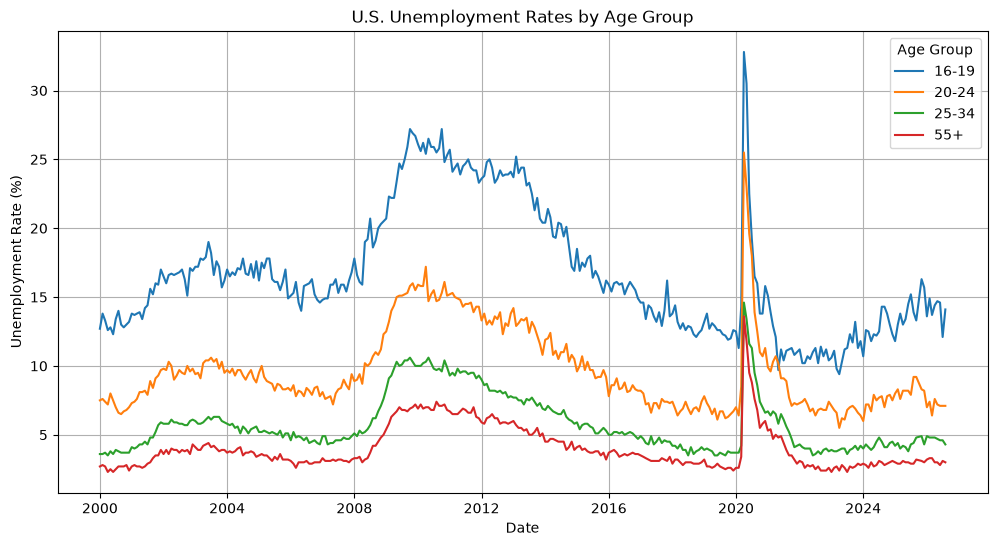

In [118]:
plt.figure(figsize=(12,6))

for group, data in series.items():
    plt.plot(data.index, data.values, label=group)

plt.title("U.S. Unemployment Rates by Age Group")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.legend(title="Age Group")
plt.grid(True)
plt.show()

In [119]:
import pandas as pd

summary_stats = pd.DataFrame(series).describe().T
display(summary_stats)


,count,mean,std,min,25%,50%,75%,max
16-19,320.0,16.729688,4.567394,9.4,13.275,15.90,19.000,32.8
20-24,320.0,9.678281,2.992903,5.5,7.400,8.85,10.800,25.5
25-34,320.0,5.782656,2.048079,3.5,4.300,5.10,6.525,14.6
55+,320.0,4.027344,1.580805,2.3,3.000,3.50,4.525,13.6
